In [2]:
import pandas as pd
#to load dataset
df=pd.read_csv('loan_approval_dataset.csv')
print(df)

    Annual_Income  CIBIL_Score  Account_Age  Loan_Amount Loan_Status
0          300000          550            1       500000    Rejected
1          800000          780            5       300000    Approved
2          450000          620            2       600000    Rejected
3         1200000          820            8       500000    Approved
4          600000          700            4       400000    Approved
5          250000          580            1       300000    Rejected
6          900000          750            6       450000    Approved
7          350000          600            2       700000    Rejected
8         1500000          850           10       600000    Approved
9          400000          630            3       550000    Rejected
10         700000          720            5       350000    Approved
11         280000          520            1       400000    Rejected
12        1100000          790            7       500000    Approved
13         500000          650    

In [3]:
#dataset information
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Annual_Income  20 non-null     int64 
 1   CIBIL_Score    20 non-null     int64 
 2   Account_Age    20 non-null     int64 
 3   Loan_Amount    20 non-null     int64 
 4   Loan_Status    20 non-null     object
dtypes: int64(4), object(1)
memory usage: 928.0+ bytes
None


In [4]:
#dataset statistical analysis
print(df.describe())

       Annual_Income  CIBIL_Score  Account_Age    Loan_Amount
count   2.000000e+01    20.000000    20.000000      20.000000
mean    6.775000e+05   683.500000     4.150000  495000.000000
std     3.786385e+05   102.509306     2.814904  130686.446766
min     2.500000e+05   520.000000     1.000000  300000.000000
25%     3.725000e+05   597.500000     2.000000  400000.000000
50%     5.500000e+05   675.000000     3.500000  500000.000000
75%     9.125000e+05   772.500000     6.000000  562500.000000
max     1.500000e+06   850.000000    10.000000  800000.000000


In [5]:
#to find null values
print('Null values:',df.isnull().sum())

Null values: Annual_Income    0
CIBIL_Score      0
Account_Age      0
Loan_Amount      0
Loan_Status      0
dtype: int64


In [6]:
#to find duplicate or repeated values
print('repeated records:',df.duplicated().sum())

repeated records: 0


In [7]:
#to convert into text data to numerical values
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['Loan_Status']=le.fit_transform(df['Loan_Status'])
print("after preprocessing...")

after preprocessing...


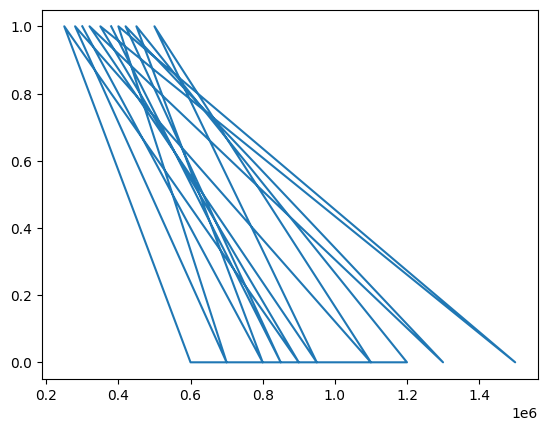

In [8]:
#data visualization
import matplotlib.pyplot as plt
plt.plot(df['Annual_Income'],df['Loan_Status'])

In [9]:
#data spliting training and testing
from sklearn.model_selection import train_test_split
inputs_x=df[['Annual_Income','CIBIL_Score','Account_Age','Loan_Amount']]
output_y=df['Loan_Status']
x_train,x_test,y_train,y_test=train_test_split(inputs_x,output_y,test_size=0.2,random_state=42)
print('training dataset:\n',x_train)
print('training outputs:\n',y_train)

training dataset:
     Annual_Income  CIBIL_Score  Account_Age  Loan_Amount
8         1500000          850           10       600000
5          250000          580            1       300000
11         280000          520            1       400000
3         1200000          820            8       500000
18         850000          760            5       400000
16        1300000          810            9       550000
13         500000          650            2       800000
2          450000          620            2       600000
9          400000          630            3       550000
19         380000          590            2       500000
4          600000          700            4       400000
12        1100000          790            7       500000
7          350000          600            2       700000
10         700000          720            5       350000
14         950000          770            6       400000
6          900000          750            6       450000
training out

In [10]:
#feature scaling
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
x_train_scaled=ss.fit_transform(x_train)
x_test_scaled=ss.transform(x_test)
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train_scaled,y_train)
print('model trained successfully..')

model trained successfully..


In [11]:
#model selection
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train_scaled,y_train)
print('model trained successfully...')
prediction_testing=model.predict(x_test_scaled)
print('testing prediction values:\n',prediction_testing)
print('actual testing values:\n',y_test)
print(df)

model trained successfully...
testing prediction values:
 [1 1 1 0]
actual testing values:
 0     1
17    1
15    1
1     0
Name: Loan_Status, dtype: int64
    Annual_Income  CIBIL_Score  Account_Age  Loan_Amount  Loan_Status
0          300000          550            1       500000            1
1          800000          780            5       300000            0
2          450000          620            2       600000            1
3         1200000          820            8       500000            0
4          600000          700            4       400000            0
5          250000          580            1       300000            1
6          900000          750            6       450000            0
7          350000          600            2       700000            1
8         1500000          850           10       600000            0
9          400000          630            3       550000            1
10         700000          720            5       350000            0
11  

In [12]:
#to find accuracy
from sklearn.metrics import accuracy_score,precision_score,recall_score
print('accuracy score:',accuracy_score(y_test,prediction_testing))
print('precision score:',precision_score(y_test,prediction_testing))
print('recall score:',recall_score(y_test,prediction_testing))
new=pd.DataFrame({
    "Annual_Income":[800000],
    "CIBIL_Score":[780],
    "Account_Age":[5],
    "Loan_Amount":[300000]
})
scaled_new=ss.transform(new)
new_prediction=model.predict(scaled_new)
if new_prediction[0]==1:
    print("Loan Rejected...")
else:
    print("loan approved...")
print(new_prediction)

accuracy score: 1.0
precision score: 1.0
recall score: 1.0
loan approved...
[0]
